In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones y duraciones (en días) se adjunta.

In [4]:
pregunta_1 = "1. Dibuje el grafo PERT y numere sus nodos.  "
pregunta_2 = "2. Construya la matriz de Zaderenko y calcule con ella los tiempos más tempranos y más tardíos de cada nodo. ¿Cuál es la duración del proyecto?  "
pregunta_3 = "3. Calcule el calendario del proyecto: inicio y fin más tempranos y más tardíos de cada actividad.  "
pregunta_4 = "4. Dibuje el diagrama de Gantt con las actividades en su inicio más temprano, con las flechas de prelación entre barras, e indique sobre él las holguras.  "
pregunta_5 = "5. La actividad F va a durar 2 días más de lo previsto. Recalcule la duración del proyecto y explique el resultado a partir de la holgura de F.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje el grafo PERT y numere sus nodos.  

2. Construya la matriz de Zaderenko y calcule con ella los tiempos más tempranos y más tardíos de cada nodo. ¿Cuál es la duración del proyecto?  

3. Calcule el calendario del proyecto: inicio y fin más tempranos y más tardíos de cada actividad.  

4. Dibuje el diagrama de Gantt con las actividades en su inicio más temprano, con las flechas de prelación entre barras, e indique sobre él las holguras.  

5. La actividad F va a durar 2 días más de lo previsto. Recalcule la duración del proyecto y explique el resultado a partir de la holgura de F.  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 2       ),
    ('B'     , '---'      , 6       ),
    ('C'     , '---'      , 5       ),
    ('D'     , 'A,B'      , 8       ),
    ('E'     , 'D'        , 3       ),
    ('F'     , 'C,E'      , 5       ),
    ('G'     , 'C,E'      , 3       ),
    ('H'     , 'D'        , 7       ),
    ('I'     , 'G'        , 4       ),
    ('J'     , 'F,H,I'    , 5       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,2
B,---,6
C,---,5
D,"A,B",8
E,D,3
F,"C,E",5
G,"C,E",3
H,D,7
I,G,4


El proyecto corresponde a la producción de un cortometraje; las actividades son las siguientes (las duraciones del cuadro están en días).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Guion definitivo',
    'B': 'Casting',
    'C': 'Localizaciones y permisos',
    'D': 'Diseño de vestuario y atrezo',
    'E': 'Plan de rodaje',
    'F': 'Ensayos con los actores',
    'G': 'Rodaje de exteriores',
    'H': 'Rodaje en plató',
    'I': 'Grabación de sonido directo',
    'J': 'Montaje',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Guion definitivo
B,Casting
C,Localizaciones y permisos
D,Diseño de vestuario y atrezo
E,Plan de rodaje
F,Ensayos con los actores
G,Rodaje de exteriores
H,Rodaje en plató
I,Grabación de sonido directo
J,Montaje


# Resolución

In [7]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Dibuje el grafo PERT y numere sus nodos.  

In [9]:
#| tbl-cap: "Cuadro de prelaciones expandido"
#| label: tbl-prelacionesExpandido
prelaciones.display_immediate_linkage_matrix()

,A,B,C,D,E,F,G,H,I,J
activities,,,,,,,,,,
A,,,,,,,,,,
B,,,,,,,,,,
C,,,,,,,,,,
D,True,True,,,,,,,,
E,,,,True,,,,,,
F,,,True,,True,,,,,
G,,,True,,True,,,,,
H,,,,True,,,,,,
I,,,,,,,True,,,


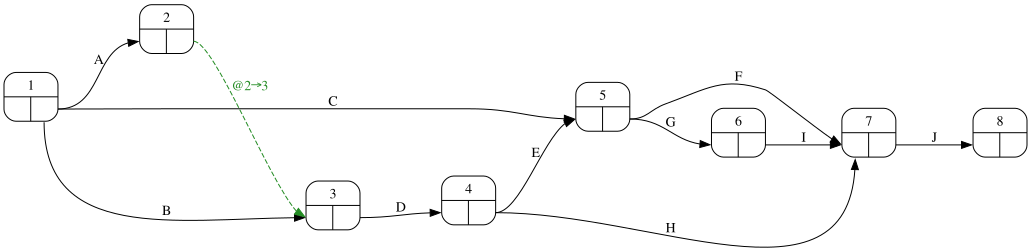

In [10]:
#| fig-cap: "Grafo PERT con numeración de nodos"
#| label: fig-pert
proyecto.pert(durations=False, ranksep=1)

## Apartado 2

In [11]:
display(Markdown(pregunta_2))

2. Construya la matriz de Zaderenko y calcule con ella los tiempos más tempranos y más tardíos de cada nodo. ¿Cuál es la duración del proyecto?  

En la matriz de Zaderenko la casilla (i, j) contiene la duración de la actividad que va del nodo i al nodo j (cero para las ficticias). El tiempo más temprano de un nodo es el máximo, sobre su columna, de «tiempo temprano del origen más duración»; el más tardío es el mínimo, sobre su fila, de «tiempo tardío del destino menos duración». Los tempranos se calculan de izquierda a derecha y los tardíos de derecha a izquierda, partiendo del tiempo temprano del último nodo.

Matriz de Zaderenko paso a paso. El primer paso muestra el resultado final; a partir del siguiente se construye desde el principio (avance con los botones):

In [12]:
#| tbl-cap: "Matriz de Zaderenko"
#| label: tbl-zaderenko
proyecto.display_zaderenko_pasos(datos_proyecto['duration'])

,1,2,3,4,5,6,7,8,early
1,,2.0,6.0,,5.0,,,,0.0
2,,,0.0,,,,,,2.0
3,,,,8.0,,,,,6.0
4,,,,,3.0,,7.0,,14.0
5,,,,,,3.0,5.0,,17.0
6,,,,,,,4.0,,20.0
7,,,,,,,,5.0,24.0
8,,,,,,,,,29.0
late,0.0,6.0,6.0,14.0,17.0,20.0,24.0,29.0,


In [13]:
#| tbl-cap: "Tiempos tempranos y tardíos de los nodos"
#| label: tbl-tiemposNodos
resultados_pert = proyecto.calculate_pert(durations=datos_proyecto['duration'])
resultados_pert['nodes']

,early,late
1,0,0
2,2,6
3,6,6
4,14,14
5,17,17
6,20,20
7,24,24
8,29,29


Cada tiempo temprano es el máximo, sobre los arcos que llegan al nodo, de «tiempo temprano del origen + duración del arco»; cada tiempo tardío, el mínimo, sobre los arcos que salen, de «tiempo tardío del destino − duración». Las ficticias (@) aportan duración 0. Las tablas recogen los candidatos que se comparan en cada nodo.

In [14]:
#| tbl-cap: "Tiempos tempranos: candidatos en cada nodo (de izquierda a derecha)"
#| label: tbl-tempranosPaso
tiempos_tempranos, tiempos_tardios = detalle_tiempos_nodos(proyecto, datos_proyecto['duration'])
tiempos_tempranos

,candidatos t_i + d_ij,tiempo temprano = máx
nodo,,
1,nodo inicial,0
2,A: 0 + 2 = 2,2
3,B: 0 + 6 = 6; @2→3: 2 + 0 = 2,6
4,D: 6 + 8 = 14,14
5,C: 0 + 5 = 5; E: 14 + 3 = 17,17
6,G: 17 + 3 = 20,20
7,H: 14 + 7 = 21; F: 17 + 5 = 22; I: 20 + 4 = 24,24
8,J: 24 + 5 = 29,29


In [15]:
#| tbl-cap: "Tiempos tardíos: candidatos en cada nodo (de derecha a izquierda)"
#| label: tbl-tardiosPaso
tiempos_tardios

,candidatos t*_j − d_ij,tiempo tardío = mín
nodo,,
8,nodo final (= su tiempo temprano),29
7,J: 29 − 5 = 24,24
6,I: 24 − 4 = 20,20
5,G: 20 − 3 = 17; F: 24 − 5 = 19,17
4,H: 24 − 7 = 17; E: 17 − 3 = 14,14
3,D: 14 − 8 = 6,6
2,@2→3: 6 − 0 = 6,6
1,A: 6 − 2 = 4; C: 17 − 5 = 12; B: 6 − 6 = 0,0


In [16]:
duracion_proyecto = proyecto.duration(datos_proyecto['duration'])
Markdown(f'La duración del proyecto es el tiempo más temprano del último nodo: {duracion_proyecto} días.')

La duración del proyecto es el tiempo más temprano del último nodo: 29 días.

## Apartado 3

In [17]:
display(Markdown(pregunta_3))

3. Calcule el calendario del proyecto: inicio y fin más tempranos y más tardíos de cada actividad.  

Para una actividad que va del nodo i al nodo j: el inicio más temprano es el tiempo temprano de i, el fin más temprano es ese inicio más la duración, el fin más tardío es el tiempo tardío de j y el inicio más tardío es ese fin menos la duración.

In [18]:
#| tbl-cap: "Calendario del proyecto"
#| label: tbl-calendario
calendario = proyecto.calendar(datos_proyecto['duration'])
calendario[['inicio_mas_temprano', 'fin_mas_temprano', 'inicio_mas_tardio', 'fin_mas_tardio', 'H_total']]

,inicio_mas_temprano,fin_mas_temprano,inicio_mas_tardio,fin_mas_tardio,H_total
activity,,,,,
A,0,2,4,6,4
B,0,6,0,6,0
C,0,5,12,17,12
D,6,14,6,14,0
E,14,17,14,17,0
F,17,22,19,24,2
G,17,20,17,20,0
H,14,21,17,24,3
I,20,24,20,24,0


In [19]:
#| tbl-cap: "Fechas de cada actividad a partir de los tiempos de sus nodos"
#| label: tbl-fechasPaso
detalle_holguras(calendario, prelaciones)[['ES = máx EF pred.', 'EF = ES + d', 'LF = mín LS suc.', 'LS = LF − d', 'H_total = LS − ES']]

,ES = máx EF pred.,EF = ES + d,LF = mín LS suc.,LS = LF − d,H_total = LS − ES
actividad,,,,,
A,inicial → 0,0 + 2 = 2,mín(D: 6) = 6,6 − 2 = 4,4 − 0 = 4
B,inicial → 0,0 + 6 = 6,mín(D: 6) = 6,6 − 6 = 0,0 − 0 = 0
C,inicial → 0,0 + 5 = 5,"mín(F: 19, G: 17) = 17",17 − 5 = 12,12 − 0 = 12
D,"máx(A: 2, B: 6) = 6",6 + 8 = 14,"mín(E: 14, H: 17) = 14",14 − 8 = 6,6 − 6 = 0
E,máx(D: 14) = 14,14 + 3 = 17,"mín(F: 19, G: 17) = 17",17 − 3 = 14,14 − 14 = 0
F,"máx(C: 5, E: 17) = 17",17 + 5 = 22,mín(J: 24) = 24,24 − 5 = 19,19 − 17 = 2
G,"máx(C: 5, E: 17) = 17",17 + 3 = 20,mín(I: 20) = 20,20 − 3 = 17,17 − 17 = 0
H,máx(D: 14) = 14,14 + 7 = 21,mín(J: 24) = 24,24 − 7 = 17,17 − 14 = 3
I,máx(G: 20) = 20,20 + 4 = 24,mín(J: 24) = 24,24 − 4 = 20,20 − 20 = 0


Cálculo de los tiempos tempranos y tardíos de los sucesos y de las holguras totales paso a paso. El primer paso muestra el grafo resuelto; a partir del siguiente se calcula desde el principio (avance con los botones):

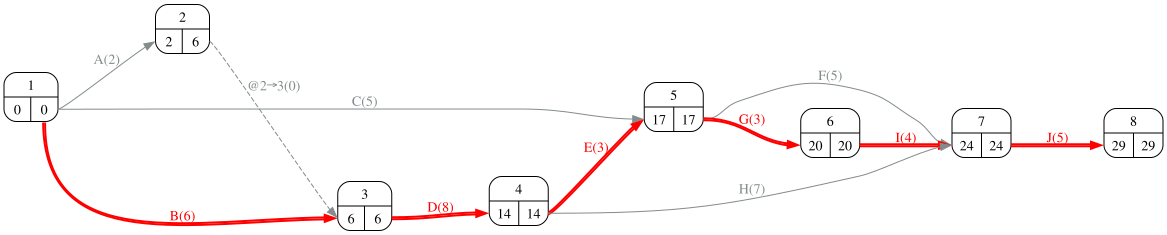

In [20]:
#| fig-cap: "Grafo PERT con tiempos de los nodos y camino crítico"
#| label: fig-pertTiempos
proyecto.display_pert_pasos(datos_proyecto['duration'])

## Apartado 4

In [21]:
display(Markdown(pregunta_4))

4. Dibuje el diagrama de Gantt con las actividades en su inicio más temprano, con las flechas de prelación entre barras, e indique sobre él las holguras.  

Las flechas unen el final de cada predecesora con el inicio de su sucesora; en rojo, las prelaciones críticas (sin hueco entre barras críticas).

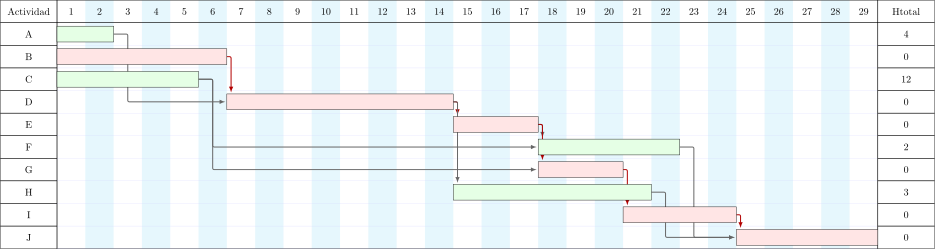

In [22]:
#| fig-cap: "Diagrama de Gantt (inicios más tempranos) con flechas de prelación y holguras"
#| label: fig-gantt
gantt_df, dibujo = proyecto.gantt(datos_proyecto, 'duration', holguras=True, tikz=True, params=GANTT_PARAMS)
pinta_tikz(dibujo)

## Apartado 5

In [23]:
display(Markdown(pregunta_5))

5. La actividad F va a durar 2 días más de lo previsto. Recalcule la duración del proyecto y explique el resultado a partir de la holgura de F.  

In [24]:
holgura = int(calendario.loc['F', 'H_total'])
duraciones_nuevas = datos_proyecto['duration'].copy()
duraciones_nuevas['F'] += 2
duracion_nueva = proyecto.duration(duraciones_nuevas)
Markdown(f'La holgura total de F es {holgura} días. Un retraso de 2 días '
         f'{"no " if 2 <= holgura else ""}supera esa holgura, y la duración del proyecto pasa de '
         f'{duracion_proyecto} a {duracion_nueva} días.')

La holgura total de F es 2 días. Un retraso de 2 días no supera esa holgura, y la duración del proyecto pasa de 29 a 29 días.

In [25]:
#| tbl-cap: "Calendario con la nueva duración"
#| label: tbl-calendarioNuevo
proyecto.calendar(duraciones_nuevas)[['inicio_mas_temprano', 'fin_mas_temprano', 'inicio_mas_tardio', 'fin_mas_tardio', 'H_total']]

,inicio_mas_temprano,fin_mas_temprano,inicio_mas_tardio,fin_mas_tardio,H_total
activity,,,,,
A,0,2,4,6,4
B,0,6,0,6,0
C,0,5,12,17,12
D,6,14,6,14,0
E,14,17,14,17,0
F,17,24,17,24,0
G,17,20,17,20,0
H,14,21,17,24,3
I,20,24,20,24,0
